In [1]:
import pandas as pd
from pandasql import sqldf
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv('/home/art/olist_data/olist_orders_dataset.csv')
customers = pd.read_csv('/home/art/olist_data/olist_customers_dataset.csv')

print("Данные загружены")
print("orders:", orders.shape)
print("customers:", customers.shape)

Данные загружены
orders: (99441, 8)
customers: (99441, 5)


In [2]:
cohort_data = sqldf("""
    WITH first_order AS (
        SELECT
            customers.customer_unique_id,
            MIN(orders.order_purchase_timestamp) AS first_order_date
        FROM orders
        JOIN customers ON orders.customer_id = customers.customer_id
        GROUP BY customers.customer_unique_id
    ),
    cohort_size AS (
        SELECT
            strftime('%Y-%m', first_order_date) AS cohort_month,
            COUNT(DISTINCT customer_unique_id) AS cohort_customers
        FROM first_order
        GROUP BY cohort_month
    ),
    customer_orders AS (
        SELECT
            customers.customer_unique_id,
            strftime('%Y-%m', orders.order_purchase_timestamp) AS order_month
        FROM orders
        JOIN customers ON orders.customer_id = customers.customer_id
        GROUP BY customers.customer_unique_id, order_month
    ),
    cohort_activity AS (
        SELECT
            strftime('%Y-%m', first_order.first_order_date) AS cohort_month,
            customer_orders.order_month,
            COUNT(DISTINCT customer_orders.customer_unique_id) AS active_customers
        FROM first_order
        JOIN customer_orders ON first_order.customer_unique_id = customer_orders.customer_unique_id
        GROUP BY cohort_month, customer_orders.order_month
    )
    SELECT
        cohort_activity.cohort_month,
        cohort_activity.order_month,
        cohort_activity.active_customers,
        cohort_size.cohort_customers,
        ROUND(cohort_activity.active_customers * 100.0 / cohort_size.cohort_customers, 2) AS retention_pct
    FROM cohort_activity
    JOIN cohort_size ON cohort_activity.cohort_month = cohort_size.cohort_month
    ORDER BY cohort_activity.cohort_month, cohort_activity.order_month
""")

print("Строк в cohort_data:", cohort_data.shape[0])
cohort_data.head(10)

Строк в cohort_data: 225


,cohort_month,order_month,active_customers,cohort_customers,retention_pct
0,2016-09,2016-09,4,4,100.00
1,2016-10,2016-10,321,321,100.00
2,2016-10,2017-04,1,321,0.31
3,2016-10,2017-07,1,321,0.31
4,2016-10,2017-09,1,321,0.31
5,2016-10,2017-11,1,321,0.31
6,2016-10,2018-01,1,321,0.31
7,2016-10,2018-03,1,321,0.31
8,2016-10,2018-05,2,321,0.62
9,2016-10,2018-06,2,321,0.62


In [3]:
retention_matrix = cohort_data.pivot_table(
    index = 'cohort_month',
    columns = 'order_month',
    values = 'retention_pct'
)

print('Размеры матрицы:', retention_matrix.shape)
retention_matrix.head(10)

Размеры матрицы: (25, 25)


order_month,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,...,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10
cohort_month,,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,NaN,100.0,NaN,NaN,NaN,NaN,0.31,NaN,NaN,0.31,...,0.31,NaN,0.31,NaN,0.62,0.62,NaN,NaN,NaN,NaN
2016-12,NaN,NaN,100.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,NaN,NaN,NaN,100.0,0.39,0.26,0.13,0.39,0.13,0.52,...,0.79,0.39,0.13,0.13,0.26,0.39,NaN,0.13,NaN,NaN
2017-02,NaN,NaN,NaN,NaN,100.00,0.23,0.29,0.11,0.40,0.11,...,0.29,0.17,0.17,0.11,0.06,0.06,0.23,NaN,NaN,NaN
2017-03,NaN,NaN,NaN,NaN,NaN,100.00,0.49,0.38,0.38,0.34,...,0.38,0.15,0.23,0.11,0.15,0.23,0.08,0.15,NaN,NaN
2017-04,NaN,NaN,NaN,NaN,NaN,NaN,100.00,0.60,0.21,0.17,...,0.17,0.26,0.09,0.09,0.04,0.09,0.09,0.21,NaN,NaN
2017-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,0.50,0.50,...,0.25,0.31,0.25,0.33,0.25,0.03,0.19,0.25,NaN,NaN
2017-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,0.48,...,0.22,0.13,0.22,0.32,0.35,0.16,0.13,0.19,NaN,NaN


In [4]:
cohort_data['cohort_index'] = (
    (pd.to_datetime(cohort_data['order_month']).dt.year - pd.to_datetime(cohort_data['cohort_month']).dt.year) * 12
    + (pd.to_datetime(cohort_data['order_month']).dt.month - pd.to_datetime(cohort_data['cohort_month']).dt.month)
)

cohort_data.head(15)

,cohort_month,order_month,active_customers,cohort_customers,retention_pct,cohort_index
0,2016-09,2016-09,4,4,100.00,0
1,2016-10,2016-10,321,321,100.00,0
2,2016-10,2017-04,1,321,0.31,6
3,2016-10,2017-07,1,321,0.31,9
4,2016-10,2017-09,1,321,0.31,11
5,2016-10,2017-11,1,321,0.31,13
6,2016-10,2018-01,1,321,0.31,15
7,2016-10,2018-03,1,321,0.31,17
8,2016-10,2018-05,2,321,0.62,19
9,2016-10,2018-06,2,321,0.62,20


In [5]:
retention_pivot = cohort_data.pivot_table(
    index='cohort_month',
    columns='cohort_index',
    values='retention_pct'
)

print("Размер:", retention_pivot.shape)
retention_pivot.head(10)

Размер: (25, 20)


cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.31,NaN,NaN,0.31,NaN,0.31,NaN,0.31,NaN,0.31,NaN,0.31,0.62,0.62
2016-12,100.0,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.39,0.26,0.13,0.39,0.13,0.52,0.13,0.13,NaN,0.39,0.13,0.79,0.39,0.13,0.13,0.26,0.39,0.13,NaN
2017-02,100.0,0.23,0.29,0.11,0.40,0.11,0.23,0.17,0.17,0.23,0.11,0.29,0.17,0.17,0.11,0.06,0.06,0.23,NaN,NaN
2017-03,100.0,0.49,0.38,0.38,0.34,0.15,0.15,0.30,0.34,0.08,0.38,0.15,0.23,0.11,0.15,0.23,0.08,0.15,NaN,NaN
2017-04,100.0,0.60,0.21,0.17,0.34,0.26,0.34,0.30,0.30,0.17,0.26,0.09,0.09,0.04,0.09,0.09,0.21,NaN,NaN,NaN
2017-05,100.0,0.50,0.50,0.39,0.31,0.33,0.42,0.17,0.25,0.31,0.25,0.33,0.25,0.03,0.19,0.25,NaN,NaN,NaN,NaN
2017-06,100.0,0.48,0.35,0.41,0.25,0.38,0.38,0.22,0.13,0.22,0.32,0.35,0.16,0.13,0.19,NaN,NaN,NaN,NaN,NaN


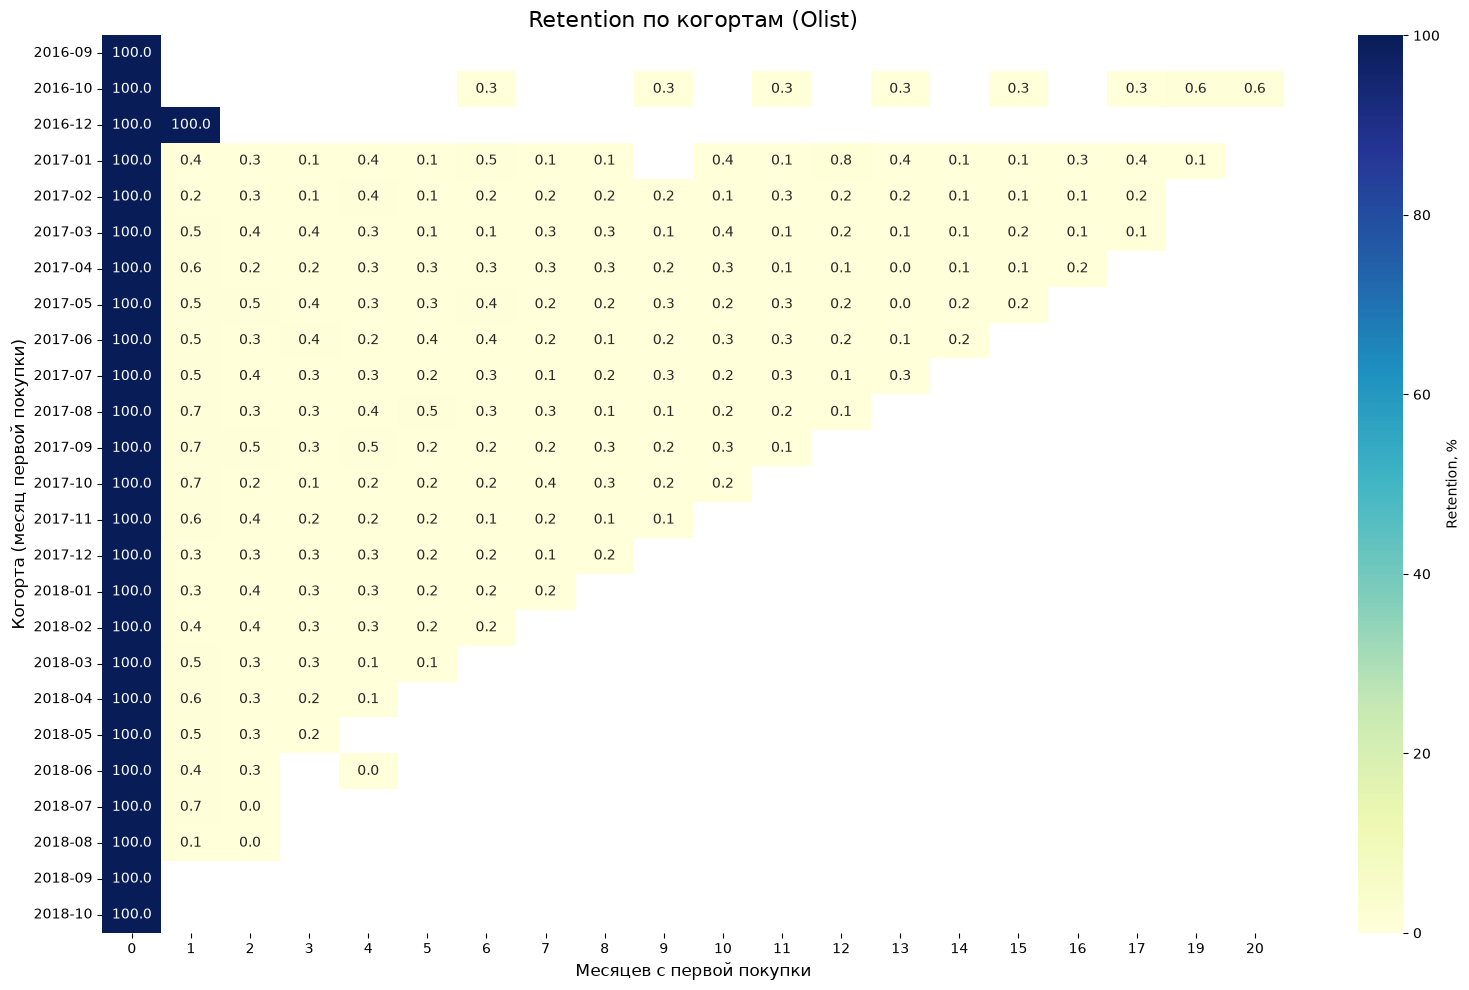

In [15]:
plt.figure(figsize = (16,10));
sns.heatmap(
    retention_pivot,
    annot=True,
    fmt = '.1f',
    cmap='YlGnBu',
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Retention, %'}
)
plt.title('Retention по когортам (Olist)', fontsize = 16)
plt.xlabel('Месяцев с первой покупки', fontsize = 12) 
plt.ylabel('Когорта (месяц первой покупки)', fontsize = 12)
plt.tight_layout()
plt.show()

In [12]:
# 2016-12, 1 месяц: когорта 2016-12 состоит из 1 клиента, следовательно retention в следующем месяце 100% от 1 человека.
# Аномалия обусловлена недостаточной выборкой

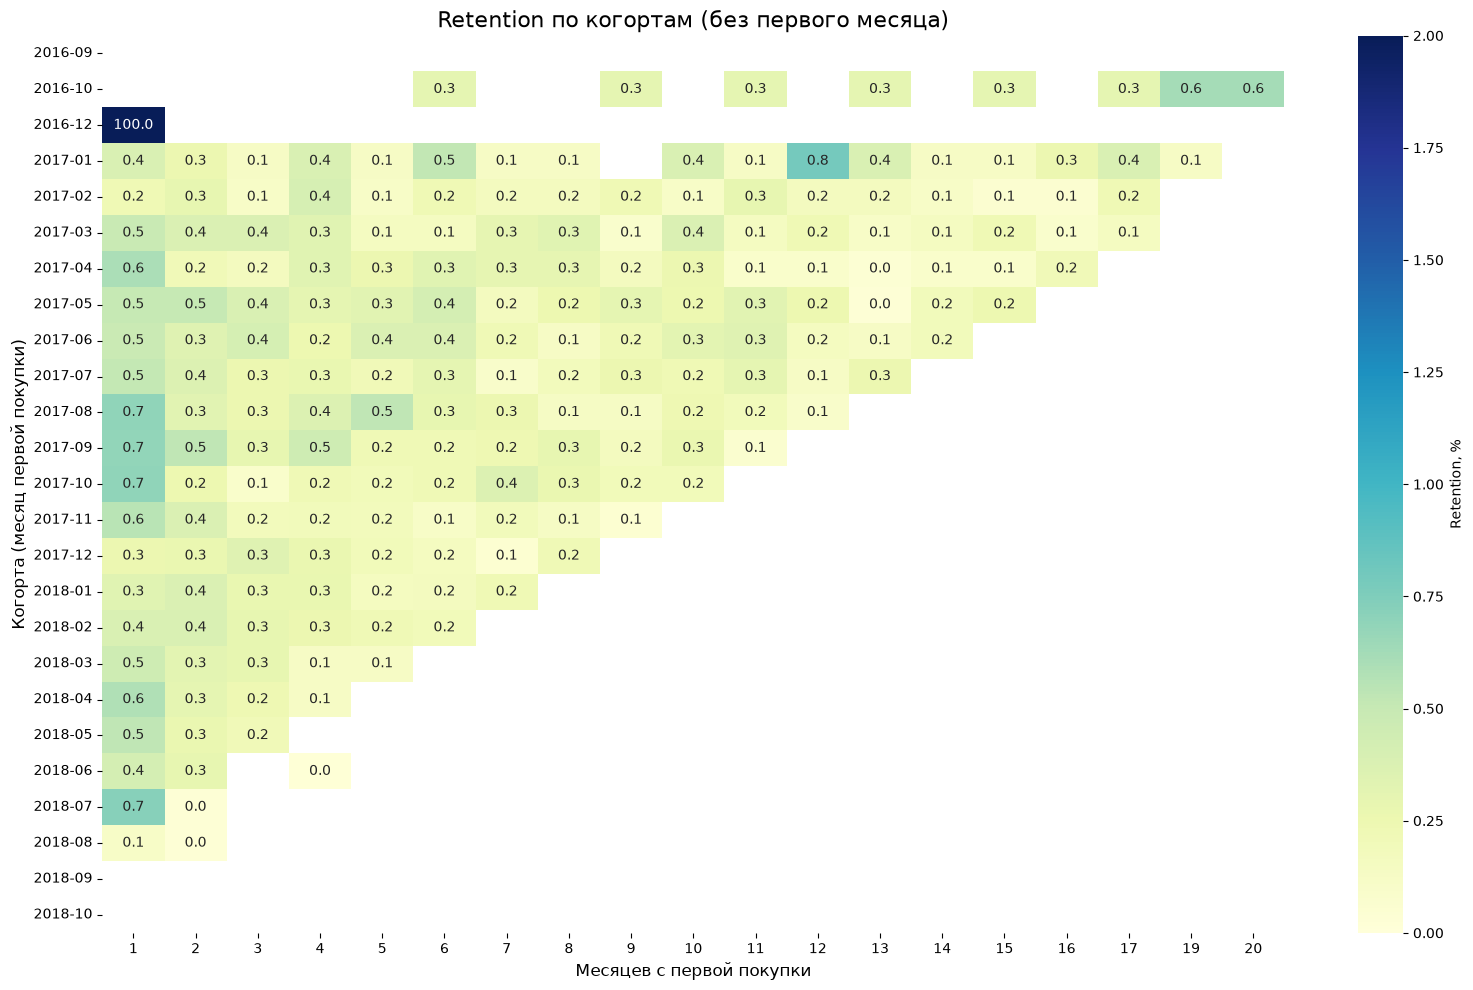

In [16]:
retention_pivot_no_diag = retention_pivot.drop(columns=[0]).round(2)

plt.figure(figsize=(16, 10))

sns.heatmap(
    retention_pivot_no_diag,
    annot=True,
    fmt = '.1f',
    cmap='YlGnBu',
    vmin=0,
    vmax=2,
    cbar_kws={'label': 'Retention, %'}
)

plt.title('Retention по когортам (без первого месяца)', fontsize=16)
plt.xlabel('Месяцев с первой покупки', fontsize=12)
plt.ylabel('Когорта (месяц первой покупки)', fontsize=12)
plt.tight_layout()
plt.savefig('retention_heatmap_no_diag.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
avg_retention = retention_pivot.drop(columns=[0]).mean(axis=0).round(2)

print("Средний retention по месяцам от первой покупки:")
print(avg_retention)

Средний retention по месяцам от первой покупки:
cohort_index
1     5.22
2     0.31
3     0.25
4     0.27
5     0.23
6     0.27
7     0.21
8     0.21
9     0.19
10    0.26
11    0.22
12    0.24
13    0.18
14    0.14
15    0.18
16    0.15
17    0.27
19    0.38
20    0.62
dtype: float64


In [17]:
month_1_retention = retention_pivot[1].dropna().round(2)

print("Retention через 1 месяц по когортам:")
print(month_1_retention)

Retention через 1 месяц по когортам:
cohort_month
2016-12    100.00
2017-01      0.39
2017-02      0.23
2017-03      0.49
2017-04      0.60
2017-05      0.50
2017-06      0.48
2017-07      0.51
2017-08      0.69
2017-09      0.68
2017-10      0.69
2017-11      0.55
2017-12      0.26
2018-01      0.34
2018-02      0.39
2018-03      0.46
2018-04      0.58
2018-05      0.53
2018-06      0.42
2018-07      0.72
2018-08      0.11
Name: 1, dtype: float64


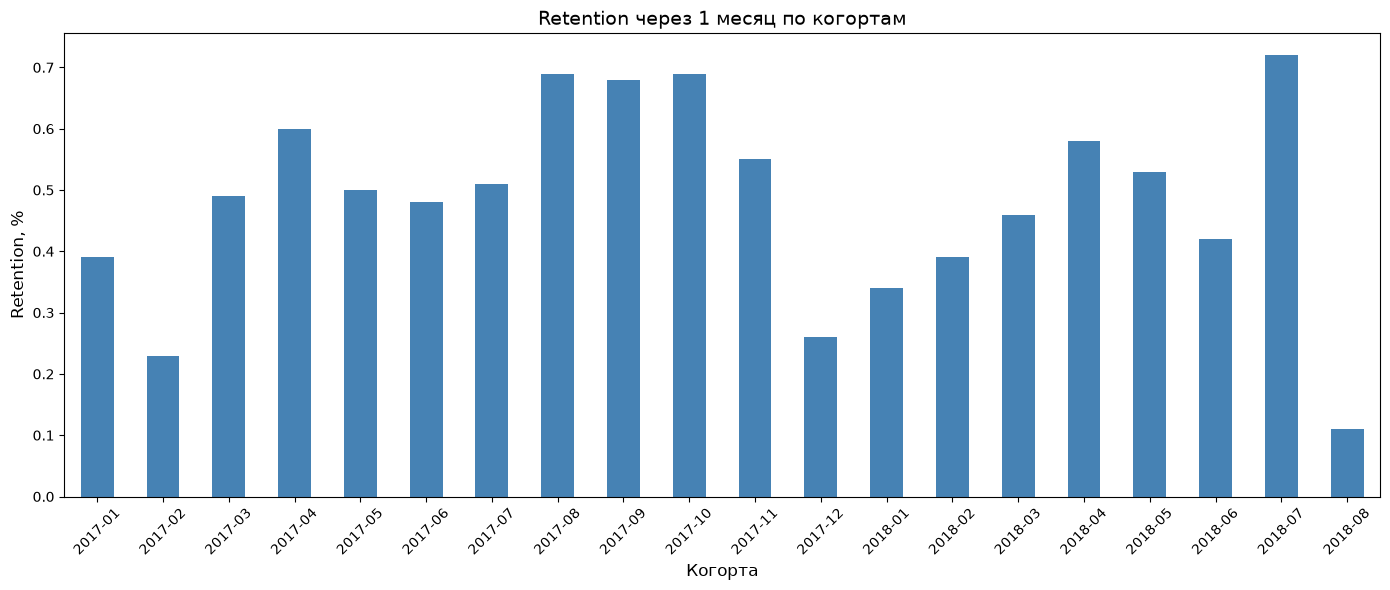

In [18]:
month_1_retention_clean = month_1_retention.drop('2016-12', errors='ignore')

plt.figure(figsize=(14, 6))
month_1_retention_clean.plot(kind='bar', color='steelblue')
plt.title('Retention через 1 месяц по когортам', fontsize=14)
plt.xlabel('Когорта', fontsize=12)
plt.ylabel('Retention, %', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('retention_month1.png', dpi=150, bbox_inches='tight')
plt.show()